# Week 2: Smart Helmet Detection — Computer Vision Application

โปรแกรม Python + OpenCV ที่โหลดโมเดล YOLO11 จาก Week 1 มาตรวจว่าผู้ขับขี่สวมหมวกกันน็อกหรือไม่ — ใส่ได้ทั้ง **ภาพ** หรือ **วิดีโอ** (วิดีโอจะถูกแบ่งออกมาเป็น 5 เฟรม)

```
ภาพ  ─────────────────────┐
                          ├→ YOLO11 (rider, with helmet) → Helmet / No Helmet → Bounding Box → สถิติ
วิดีโอ → แบ่งออกมา 5 เฟรม ─┘
```

| งานสัปดาห์ที่ 2 | ทำที่ข้อ |
|---|---|
| โหลด Model | 1 |
| เขียน Python | ทุกข้อ |
| ใช้ OpenCV | 2, 4, 5 |
| รับ Image/Video | 2 |
| Detection | 3 |
| แสดง Bounding Box | 4 |
| ประมวลผลและคำนวณสถิติ | 5 |

**Deliverable:** Python Application ที่สามารถทำงานได้ → รันทุก cell ตามลำดับ

### 0. เตรียม library และตั้งค่า

- `ultralytics` — YOLO11 สำหรับตรวจจับ
- `cv2` (OpenCV) — อ่านภาพ/วิดีโอ, ดึงเฟรม, วาดกรอบ
- `pandas`, `matplotlib` — ตารางสถิติและกราฟ
- ค่าทั้งหมดตั้งไว้ใน cell ที่สองที่เดียว
- **รันบน Colab:** จะ mount Google Drive แล้วใช้โฟลเดอร์ `MyDrive/helmet_week1` (ที่ Week 1 บันทึกโมเดลไว้) ถ้าไม่พบโมเดลจะขึ้นปุ่มให้อัปโหลด
- **รันบนเครื่อง (VS Code):** ใช้ไฟล์ในโฟลเดอร์โปรเจกต์

In [1]:
import importlib.util
import subprocess
import sys

# ติดตั้ง ultralytics ถ้ายังไม่มี (บน Colab ต้องติดตั้ง, บนเครื่องที่ใช้ .venv มีแล้ว)
if importlib.util.find_spec("ultralytics") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])

In [2]:
import json
import math
from dataclasses import dataclass, field
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from ultralytics import YOLO

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive, files
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/helmet_week1")   # โฟลเดอร์ที่ Week 1 บันทึกโมเดลไว้
else:
    BASE_DIR = Path(".")                                      # โฟลเดอร์โปรเจกต์บนเครื่อง

MODEL_PATH = BASE_DIR / "yolo_10epoch_best.pt"
OUTPUT_DIR = BASE_DIR / "output" / "notebook"

# Input: ไฟล์ภาพ / โฟลเดอร์ภาพ / ไฟล์วิดีโอ
#   None -> Colab: ขึ้นปุ่มให้อัปโหลด (ภาพหลายไฟล์ หรือวิดีโอ 1 ไฟล์) / บนเครื่อง: ใช้ images/samples
INPUT_PATH = None
N_FRAMES   = 5       # วิดีโอ: จำนวนเฟรมที่แบ่งออกมาตรวจ

RIDER_CONF  = 0.25   # confidence ขั้นต่ำของ rider
HELMET_CONF = 0.25   # confidence ขั้นต่ำของหมวก
NMS_IOU     = 0.5    # กล่องคลาสเดียวกันที่ซ้อนกันเกินค่านี้ จะเหลือกล่องเดียว (กัน rider ซ้ำ)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Colab: ถ้ายังไม่มีโมเดลใน Drive ให้อัปโหลด
if IN_COLAB and not MODEL_PATH.exists():
    print("Upload model file: yolo_10epoch_best.pt")
    for name, data in files.upload().items():
        (BASE_DIR / name).write_bytes(data)


def show_images(images, titles=None, cols=3, size=5):
    """แสดงภาพ BGR (แบบ OpenCV) หลายภาพเป็นตาราง"""

    cols = min(cols, len(images))
    rows = math.ceil(len(images) / cols)
    plt.figure(figsize=(size * cols, size * rows))

    for i, img in enumerate(images):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))   # OpenCV เก็บสีแบบ BGR
        if titles:
            plt.title(titles[i])
        plt.axis("off")

    plt.tight_layout()
    plt.show()


print("OpenCV", cv2.__version__)
print("Model exists:", MODEL_PATH.exists())

OpenCV 5.0.0
Model exists: True


### 1. โหลด Model

- โหลดโมเดล YOLO11n ที่ train ไว้ใน Week 1 (`yolo_10epoch_best.pt`)
- โมเดลมี 3 คลาส: `motorcycle`, `rider`, `with helmet` — ใช้เฉพาะ `rider` และ `with helmet`
- โมเดลไม่มีคลาส "ไม่สวมหมวก" จึงต้องตัดสินเองจากตำแหน่งหมวกเทียบกับ rider (ข้อ 3)

In [3]:
model = YOLO(str(MODEL_PATH))
model.info()

CLASS_IDS = {name: i for i, name in model.names.items()}
RIDER_ID  = CLASS_IDS["rider"]
HELMET_ID = CLASS_IDS["with helmet"]

print("Classes:", model.names)
print("Rider id:", RIDER_ID, "| Helmet id:", HELMET_ID)

YOLO11n summary: 182 layers, 2,605,369 parameters, 0 gradients, 6.6 GFLOPs


Classes: {0: 'motorcycle', 1: 'rider', 2: 'with helmet'}
Rider id: 1 | Helmet id: 2


### 2. รับ Image หรือ Video (OpenCV)

ใส่ได้อย่างใดอย่างหนึ่ง — โปรแกรมดูจากนามสกุลไฟล์ว่าเป็นภาพหรือวิดีโอ

| Input | นามสกุล | OpenCV | ได้ออกมา |
|---|---|---|---|
| ภาพ (1 ไฟล์หรือหลายไฟล์) | `.jpg .jpeg .png .bmp .webp` | `cv2.imread()` อ่านเป็น array (สูง, กว้าง, 3) สี BGR | ภาพทุกไฟล์ |
| วิดีโอ (1 ไฟล์) | `.mp4 .avi .mov .mkv .m4v .wmv` | `cv2.VideoCapture()` อ่าน FPS / จำนวนเฟรม แล้ว `cap.set()` กระโดดไปเฟรมที่ต้องการ + `cap.read()` | **5 เฟรม** กระจายเท่า ๆ กันตลอดวิดีโอ |

- บน Colab (`INPUT_PATH = None`) จะขึ้นปุ่มให้อัปโหลด ไฟล์ที่อัปโหลดเก็บใน `helmet_week1/input/`
- เฟรมที่แบ่งจากวิดีโอบันทึกไว้ใน `OUTPUT_DIR/frames/`
- ผลที่ได้คือ `inputs` (รายการภาพ) และ `input_names` (ชื่อ) ใช้ต่อในข้อ 3–5 เหมือนกันทั้งภาพและวิดีโอ

Input type: image -> 5 images
  test_1.jpg: shape = (548, 548, 3)
  test_2.jpg: shape = (548, 548, 3)
  test_3.jpg: shape = (548, 548, 3)
  test_4.jpg: shape = (548, 548, 3)
  test_5.jpg: shape = (548, 548, 3)


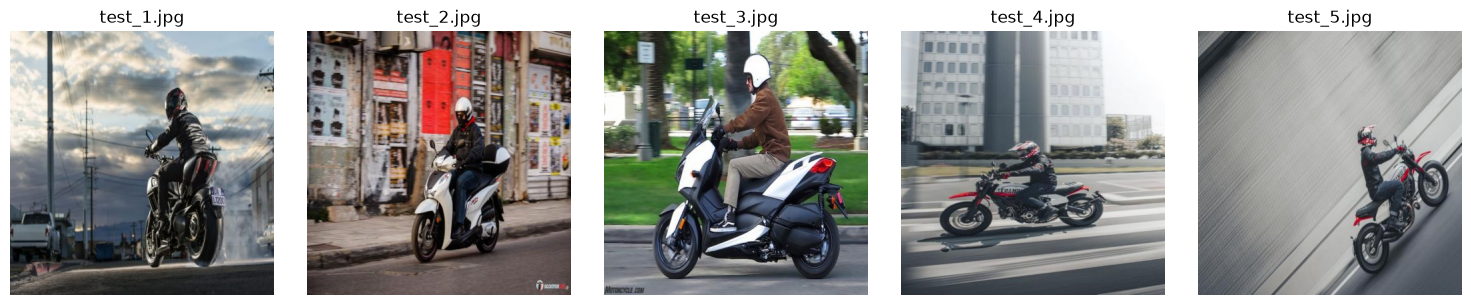

In [4]:
IMAGE_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
VIDEO_EXT = {".mp4", ".avi", ".mov", ".mkv", ".m4v", ".wmv"}


def get_input_files():
    """คืนรายการไฟล์ input (อัปโหลดบน Colab / INPUT_PATH / images/samples)"""

    if INPUT_PATH is None and IN_COLAB:
        upload_dir = BASE_DIR / "input"
        upload_dir.mkdir(parents=True, exist_ok=True)
        print("Upload image(s) or 1 video")
        paths = []
        for name, data in files.upload().items():
            (upload_dir / name).write_bytes(data)
            paths.append(upload_dir / name)
        return paths

    source = Path(INPUT_PATH) if INPUT_PATH is not None else BASE_DIR / "images" / "samples"
    if not source.exists():
        raise FileNotFoundError(f"not found: {source}")

    return sorted(source.iterdir()) if source.is_dir() else [source]


def extract_frames(video_path, n=5):
    """แบ่งวิดีโอออกมา n เฟรม กระจายเท่า ๆ กัน (ไม่เอาเฟรมแรก/สุดท้ายสุด ซึ่งมักเป็นภาพดำ)"""

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise FileNotFoundError(f"cannot open video: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS) or 30          # บางไฟล์ไม่บอก FPS (ได้ 0) ใช้ 30 แทน
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width, height = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    if total <= 0:
        raise ValueError(f"cannot read frame count: {video_path}")

    print(f"Video: {Path(video_path).name}, {width}x{height}, {fps:.0f} FPS, {total} frames ({total / fps:.1f} s)")

    frames, names = [], []
    for idx in np.linspace(0, total - 1, n + 2)[1:-1].astype(int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ok, frame = cap.read()
        if ok:
            frames.append(frame)
            names.append(f"frame {idx} ({idx / fps:.1f}s)")

    cap.release()
    return frames, names


input_files = get_input_files()
videos = [p for p in input_files if p.suffix.lower() in VIDEO_EXT]
image_files = [p for p in input_files if p.suffix.lower() in IMAGE_EXT]

if videos:
    INPUT_TYPE = "video"
    if len(videos) > 1:
        print(f"use first video only: {videos[0].name}")
    inputs, input_names = extract_frames(videos[0], N_FRAMES)

    # บันทึกเฟรมที่แบ่งออกมา
    frame_dir = OUTPUT_DIR / "frames"
    frame_dir.mkdir(parents=True, exist_ok=True)
    for i, frame in enumerate(inputs, 1):
        cv2.imwrite(str(frame_dir / f"frame_{i}.jpg"), frame)

elif image_files:
    INPUT_TYPE = "image"
    inputs = [cv2.imread(str(p)) for p in image_files]
    input_names = [p.name for p in image_files]

else:
    raise FileNotFoundError(f"no image or video file | found: {[p.name for p in input_files]}")

print(f"Input type: {INPUT_TYPE} -> {len(inputs)} images")
for name, img in zip(input_names, inputs):
    print(f"  {name}: shape = {img.shape}")

show_images(inputs, input_names, cols=5, size=3)

### 3. Detection

**ตรวจจับ:** `model.predict()` หากล่อง `rider` และ `with helmet` แล้วกรองด้วย threshold แยกกัน (`RIDER_CONF`, `HELMET_CONF`) เพราะโมเดลมักให้ confidence ของหมวกต่ำกว่า rider และตั้ง NMS IoU = 0.5 (ค่าเริ่มต้นของ YOLO คือ 0.7) เพื่อตัดกล่อง rider ที่ซ้อนกันให้เหลือคนละกล่อง

**ตัดสินว่า rider สวมหมวกหรือไม่:**

```
 ┌─────────────┐  ← ขอบบนของ rider (ยอมให้หมวกเกินขึ้นไปได้ 10% ของความสูง)
 │   ศีรษะ      │     จุดกึ่งกลางหมวกต้องอยู่ในช่วงนี้
 ├─────────────┤  ← 50% ของความสูง
 │   ลำตัว      │
 └─────────────┘
```

1. หมวกเป็นของ rider ถ้าจุดกึ่งกลางหมวกอยู่ในครึ่งบนของกล่อง rider (กฎเดียวกับ Confusion Matrix ใน Week 1)
2. หมวก 1 ใบเป็นของ rider ได้คนเดียว ถ้าเข้าเงื่อนไขหลายคน (เช่น ซ้อนท้าย) เลือกคนที่ศีรษะอยู่ใกล้หมวกที่สุด
3. rider ที่ไม่มีหมวกจับคู่ = **No Helmet**

ผลเก็บเป็น dataclass: `Detection` (กล่อง 1 กล่อง), `Rider` (rider + หมวกที่จับคู่ได้), `FrameResult` (ผลของภาพ 1 ภาพ)

ตรวจ **ทุกภาพ / ทุกเฟรม** แล้วเก็บไว้ใน `results` (ใช้ต่อในข้อ 4–5)

In [5]:
HEAD_PART = 0.5    # ครึ่งบนของกล่อง rider = บริเวณศีรษะ
TOP_MARGIN = 0.1   # ยอมให้หมวกโผล่เหนือกล่อง rider ได้ 10% ของความสูง
HEAD_Y = 0.15      # ตำแหน่งศีรษะโดยประมาณ = 15% จากขอบบนของกล่อง rider


@dataclass
class Detection:
    box: tuple      # (x1, y1, x2, y2) พิกัด pixel
    conf: float

    @property
    def center(self):
        x1, y1, x2, y2 = self.box
        return (x1 + x2) / 2, (y1 + y2) / 2


@dataclass
class Rider(Detection):
    helmet: Detection | None = None   # หมวกที่จับคู่ได้ (None = ไม่สวมหมวก)

    @property
    def has_helmet(self):
        return self.helmet is not None


@dataclass
class FrameResult:
    riders: list = field(default_factory=list)
    unmatched_helmets: list = field(default_factory=list)   # หมวกที่ไม่มี rider จับคู่
    inference_ms: float = 0.0

    @property
    def n_riders(self):
        return len(self.riders)

    @property
    def n_helmet(self):
        return sum(r.has_helmet for r in self.riders)

    @property
    def n_no_helmet(self):
        return self.n_riders - self.n_helmet


def match_helmets(riders, helmets):
    """จับคู่หมวกให้ rider (ใส่ค่าใน rider.helmet) คืนรายการหมวกที่จับคู่ไม่ได้"""

    unmatched = []

    for helmet in sorted(helmets, key=lambda d: d.conf, reverse=True):

        hx, hy = helmet.center
        best, best_dist = None, math.inf

        for rider in riders:
            if rider.has_helmet:
                continue

            x1, y1, x2, y2 = rider.box
            h = y2 - y1
            if not (x1 <= hx <= x2 and y1 - TOP_MARGIN * h <= hy <= y1 + HEAD_PART * h):
                continue

            # ระยะจากหมวกถึงศีรษะ หารด้วยความสูง rider เพื่อให้เทียบกันได้ทุกขนาด
            dist = math.hypot(hx - (x1 + x2) / 2, hy - (y1 + HEAD_Y * h)) / h
            if dist < best_dist:
                best, best_dist = rider, dist

        if best is None:
            unmatched.append(helmet)
        else:
            best.helmet = helmet

    return unmatched


def detect(image):
    """ตรวจภาพ BGR 1 ภาพ คืนค่า FrameResult"""

    result = model.predict(
        image,
        conf=min(RIDER_CONF, HELMET_CONF),
        iou=NMS_IOU,
        classes=[RIDER_ID, HELMET_ID],
        verbose=False,
    )[0]

    riders, helmets = [], []

    for box, cls, conf in zip(result.boxes.xyxy.tolist(), result.boxes.cls.tolist(), result.boxes.conf.tolist()):
        if cls == RIDER_ID and conf >= RIDER_CONF:
            riders.append(Rider(tuple(box), conf))
        elif cls == HELMET_ID and conf >= HELMET_CONF:
            helmets.append(Detection(tuple(box), conf))

    unmatched = match_helmets(riders, helmets)

    return FrameResult(riders, unmatched, inference_ms=sum(result.speed.values()))


# ตรวจทุกภาพ / ทุกเฟรม
results = [detect(image) for image in inputs]

for name, result in zip(input_names, results):
    print(f"{name}: riders = {result.n_riders}, helmet = {result.n_helmet}, "
          f"no helmet = {result.n_no_helmet}, time = {result.inference_ms:.1f} ms")
    for i, r in enumerate(result.riders, 1):
        status = f"Helmet (helmet conf {r.helmet.conf:.2f})" if r.has_helmet else "No Helmet"
        print(f"  rider {i}: conf {r.conf:.2f}, box {tuple(int(v) for v in r.box)} -> {status}")

test_1.jpg: riders = 1, helmet = 1, no helmet = 0, time = 135.0 ms
  rider 1: conf 0.88, box (260, 82, 525, 492) -> Helmet (helmet conf 0.27)
test_2.jpg: riders = 1, helmet = 1, no helmet = 0, time = 66.0 ms
  rider 1: conf 0.82, box (205, 129, 438, 474) -> Helmet (helmet conf 0.33)
test_3.jpg: riders = 1, helmet = 0, no helmet = 1, time = 46.5 ms
  rider 1: conf 0.93, box (12, 0, 542, 519) -> No Helmet
test_4.jpg: riders = 1, helmet = 0, no helmet = 1, time = 48.4 ms
  rider 1: conf 0.76, box (101, 178, 439, 437) -> No Helmet
test_5.jpg: riders = 1, helmet = 0, no helmet = 1, time = 45.5 ms
  rider 1: conf 0.82, box (302, 180, 548, 525) -> No Helmet


### 4. แสดง Bounding Box (OpenCV)

- `cv2.rectangle()` วาดกรอบ: **เขียว** = สวมหมวก, **แดง** = ไม่สวมหมวก, **เหลือง** = หมวก
- `cv2.putText()` เขียนป้ายสถานะ + confidence บนกรอบ
- แถบสถิติต่อไว้ด้านบนของภาพ (ไม่บังกรอบ): Riders / Helmet / No helmet / Compliance
- ข้อความบนภาพเป็นภาษาอังกฤษ เพราะ `cv2.putText` ไม่รองรับภาษาไทย
- แสดง Input คู่กับ Result **ทุกภาพ / ทุกเฟรม** และบันทึกภาพผลลัพธ์ใน `OUTPUT_DIR/results/`

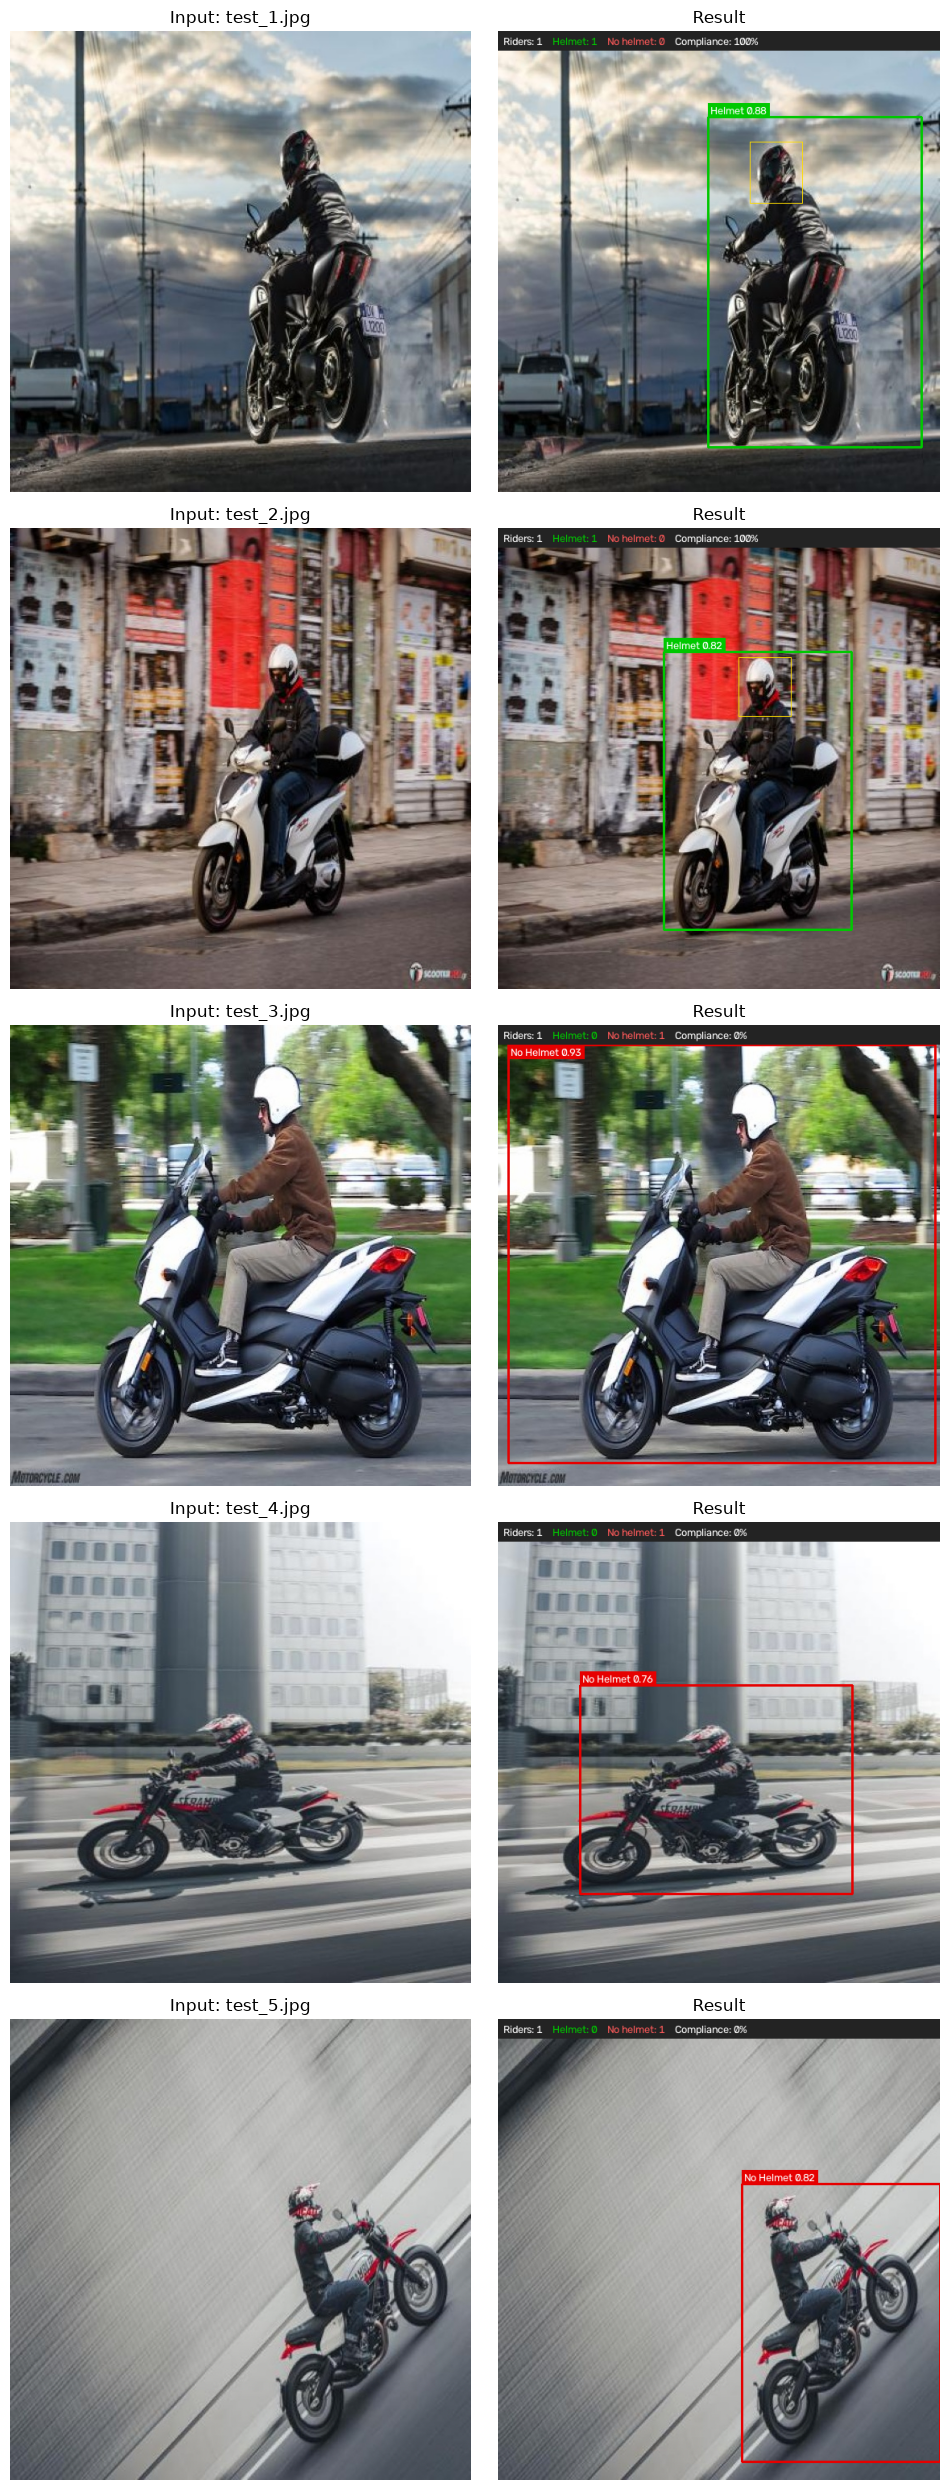

In [6]:
GREEN = (0, 200, 0)
RED = (0, 0, 230)
LIGHT_RED = (90, 90, 255)
YELLOW = (0, 220, 255)
WHITE = (255, 255, 255)
FONT = cv2.FONT_HERSHEY_SIMPLEX


def draw_detections(image, result):
    """วาดกรอบ rider (เขียว/แดง) และกรอบหมวก (เหลือง)"""

    out = image.copy()
    s = max(out.shape[:2]) / 1000                      # ปรับขนาดเส้น/ตัวอักษรตามขนาดภาพ
    thick = max(2, round(2.5 * s))
    font_scale, font_thick = max(0.45, 0.6 * s), max(1, round(1.5 * s))

    for rider in result.riders:
        x1, y1, x2, y2 = map(int, rider.box)
        color = GREEN if rider.has_helmet else RED
        text = f"{'Helmet' if rider.has_helmet else 'No Helmet'} {rider.conf:.2f}"

        cv2.rectangle(out, (x1, y1), (x2, y2), color, thick)

        # ป้ายข้อความพื้นทึบเหนือกรอบ
        (tw, th), base = cv2.getTextSize(text, FONT, font_scale, font_thick)
        ty = max(y1, th + base + 4)
        cv2.rectangle(out, (x1, ty - th - base - 4), (x1 + tw + 6, ty), color, -1)
        cv2.putText(out, text, (x1 + 3, ty - base - 2), FONT, font_scale, WHITE, font_thick, cv2.LINE_AA)

    helmets = [r.helmet for r in result.riders if r.has_helmet] + result.unmatched_helmets
    for helmet in helmets:
        hx1, hy1, hx2, hy2 = map(int, helmet.box)
        cv2.rectangle(out, (hx1, hy1), (hx2, hy2), YELLOW, max(1, thick - 1))

    return out


def add_header(image, result):
    """ต่อแถบสถิติไว้ด้านบนของภาพ"""

    w = image.shape[1]
    scale = min(max(w / 1300, 0.45), 1.0)
    thickness = max(1, round(2 * scale))
    rate = f"{result.n_helmet / result.n_riders:.0%}" if result.n_riders else "-"
    items = [
        (f"Riders: {result.n_riders}", WHITE),
        (f"Helmet: {result.n_helmet}", GREEN),
        (f"No helmet: {result.n_no_helmet}", LIGHT_RED),
        (f"Compliance: {rate}", WHITE),
    ]

    header = np.full((int(55 * scale), w, 3), (35, 35, 35), np.uint8)
    x = int(14 * scale)
    for text, color in items:
        cv2.putText(header, text, (x, int(38 * scale)), FONT, scale, color, thickness, cv2.LINE_AA)
        x += cv2.getTextSize(text, FONT, scale, thickness)[0][0] + int(28 * scale)

    return np.vstack([header, image])


def annotate(image, result):
    """กรอบตรวจจับ + แถบสถิติ"""

    return add_header(draw_detections(image, result), result)


result_dir = OUTPUT_DIR / "results"
result_dir.mkdir(parents=True, exist_ok=True)

annotated_images = [annotate(image, result) for image, result in zip(inputs, results)]
for i, annotated in enumerate(annotated_images, 1):
    cv2.imwrite(str(result_dir / f"result_{i}.jpg"), annotated)

# Input คู่กับ Result ทุกภาพ / ทุกเฟรม
pairs, titles = [], []
for name, image, annotated in zip(input_names, inputs, annotated_images):
    pairs += [image, annotated]
    titles += [f"Input: {name}", "Result"]

show_images(pairs, titles, cols=2, size=5)

### 5. ประมวลผลและคำนวณสถิติ

นำผลตรวจของทุกภาพ (หรือทั้ง 5 เฟรมของวิดีโอ) จากข้อ 3 มาทำตารางรายภาพ (`stats.csv`) สรุปรวม (`summary.json`) และกราฟ (`counts.png`)

| สถิติ | ความหมาย |
|---|---|
| `riders` | จำนวน rider ที่ตรวจพบ |
| `with_helmet` / `no_helmet` | จำนวน rider ที่สวม / ไม่สวมหมวก |
| `unmatched_helmets` | หมวกที่ไม่มี rider จับคู่ (มักเป็นคนที่โมเดลหา rider ไม่เจอ) |
| `compliance_rate` | สวมหมวก ÷ rider ทั้งหมด |
| `with_violation` | จำนวนภาพ/เฟรมที่มีคนไม่สวมหมวกอย่างน้อย 1 คน |
| `inference_ms` | เวลาที่ YOLO ใช้ต่อภาพ |

In [7]:
def rate(helmet, total):
    return round(helmet / total, 4) if total else None


# ใช้ผลตรวจจากข้อ 3 (results)
rows = [{
    "input": name,
    "riders": result.n_riders,
    "with_helmet": result.n_helmet,
    "no_helmet": result.n_no_helmet,
    "unmatched_helmets": len(result.unmatched_helmets),
    "compliance_rate": rate(result.n_helmet, result.n_riders),
    "inference_ms": round(result.inference_ms, 1),
} for name, result in zip(input_names, results)]

stats_df = pd.DataFrame(rows)
stats_df.to_csv(OUTPUT_DIR / "stats.csv", index=False)

riders, helmet = int(stats_df["riders"].sum()), int(stats_df["with_helmet"].sum())
summary = {
    "input_type": INPUT_TYPE,
    "source": videos[0].name if INPUT_TYPE == "video" else f"{len(image_files)} image file(s)",
    "images_or_frames": len(stats_df),
    "with_violation": int((stats_df["no_helmet"] > 0).sum()),
    "riders": riders,
    "with_helmet": helmet,
    "no_helmet": riders - helmet,
    "unmatched_helmets": int(stats_df["unmatched_helmets"].sum()),
    "compliance_rate": rate(helmet, riders),
    "avg_inference_ms": round(float(stats_df["inference_ms"].mean()), 1),
}

with open(OUTPUT_DIR / "summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print("========== Results ==========")
display(stats_df)
print("\n========== Summary ==========")
display(pd.Series(summary, name="value", dtype=object).to_frame())

========== Results ==========


,input,riders,with_helmet,no_helmet,unmatched_helmets,compliance_rate,inference_ms
0,test_1.jpg,1,1,0,0,1.0,135.0
1,test_2.jpg,1,1,0,0,1.0,66.0
2,test_3.jpg,1,0,1,0,0.0,46.5
3,test_4.jpg,1,0,1,0,0.0,48.4
4,test_5.jpg,1,0,1,0,0.0,45.5



========== Summary ==========


,value
input_type,image
source,5 image file(s)
images_or_frames,5
with_violation,3
riders,5
with_helmet,2
no_helmet,3
unmatched_helmets,0
compliance_rate,0.4
avg_inference_ms,68.3


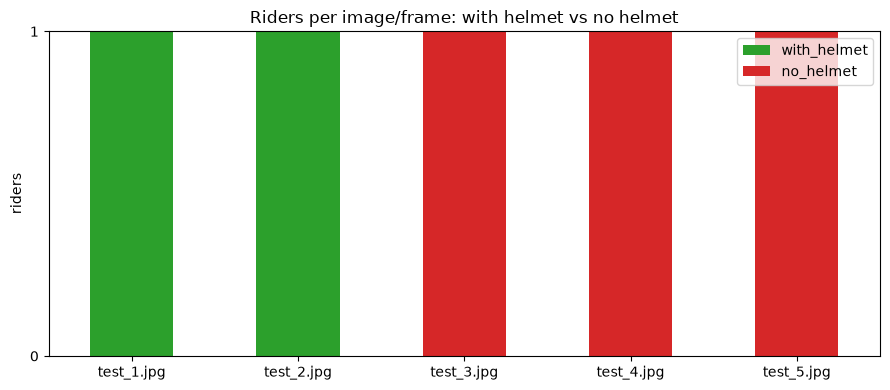

In [8]:
ax = stats_df.set_index("input")[["with_helmet", "no_helmet"]].plot(
    kind="bar", stacked=True, color=["tab:green", "tab:red"], figsize=(9, 4), rot=0,
    title="Riders per image/frame: with helmet vs no helmet")
ax.set_xlabel("")
ax.set_ylabel("riders")
ax.yaxis.get_major_locator().set_params(integer=True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "counts.png", dpi=150)
plt.show()

### ไฟล์ผลลัพธ์

In [9]:
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print(f"{str(p.relative_to(OUTPUT_DIR)):<25} {p.stat().st_size / 1024:8.1f} KB")

counts.png                    24.4 KB
results\result_1.jpg          98.8 KB
results\result_2.jpg         120.5 KB
results\result_3.jpg         126.0 KB
results\result_4.jpg          91.7 KB
results\result_5.jpg          89.3 KB
stats.csv                      0.2 KB
summary.json                   0.2 KB


### สรุป Week 2

| งานสัปดาห์ที่ 2 | ผล |
|---|---|
| โหลด Model | ✅ โหลด `yolo_10epoch_best.pt` (YOLO11n, 3 คลาส) |
| เขียน Python | ✅ ทุกขั้นเป็นฟังก์ชัน Python รันต่อกันได้ตั้งแต่ต้นจนจบ |
| ใช้ OpenCV | ✅ `imread`, `VideoCapture`, `set` / `read` (ดึงเฟรม), `rectangle`, `putText`, `imwrite` |
| รับ Image/Video | ✅ ใส่ภาพ (หลายไฟล์) หรือวิดีโอ (แบ่งเป็น 5 เฟรม) อย่างใดอย่างหนึ่ง |
| Detection | ✅ ตรวจ rider + หมวก แล้วตัดสิน Helmet / No Helmet ราย rider |
| แสดง Bounding Box | ✅ กรอบเขียว / แดง / เหลือง + แถบสถิติ บนทุกภาพ/เฟรม |
| ประมวลผลและคำนวณสถิติ | ✅ ตารางรายภาพ/เฟรม, สรุปรวม, กราฟ, บันทึก CSV / JSON |

**ผลการทดสอบ:**
- ภาพตัวอย่าง 5 ภาพ (ทุกภาพสวมหมวก): หา rider เจอครบ 5 คน แต่หาหมวกเจอ 2 คน → Compliance 40%
- วิดีโอทดสอบ 10 วินาที: แบ่งออกมา 5 เฟรม ตรวจได้ครบทุกเฟรม

**ข้อจำกัด:** โมเดลจาก Week 1 หาหมวกพลาดบ่อย (Helmet Recall บน Test set = 0.50) คนที่สวมหมวกจึงอาจถูกตัดสินเป็น No Helmet